In [2]:
import os, sys
REPO = "https://github.com/salsyaniditiani-commits/simuteh--2330511061-.git"

if not os.path.exists("/content/simuteh"):
    !git clone {REPO} /content/simuteh
os.chdir("/content/simuteh")

for f in ["notebook", "hasil", "laporan"]:
    os.makedirs(f, exist_ok=True)

if not os.path.exists("data/sintetis/citra"):
    !python src/buat_dataset_sintetis.py

os.chdir("/content/simuteh/notebook")
sys.path.append("../src")

print("Folder kerja:", os.getcwd())
print("Jumlah citra:", len(os.listdir("../data/sintetis/citra")))
print("Isi src:", os.listdir("../src"))

Cloning into '/content/simuteh'...
remote: Enumerating objects: 115, done.
remote: Counting objects: 100% (115/115), done.
remote: Compressing objects: 100% (97/97), done.
remote: Total 115 (delta 9), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (115/115), 13.43 MiB | 23.92 MiB/s, done.
Resolving deltas: 100% (9/9), done.
Selesai: 60 citra tersimpan di data/sintetis
Folder kerja: /content/simuteh/notebook
Jumlah citra: 60
Isi src: ['utils_cv.py', 'praproses.py', 'buat_dataset_sintetis.py']


teh_041.png {'rerata': 163.6, 'simpangan_baku': 38.8, 'min': 65, 'maks': 224, 'persen_gelap': 0.0, 'persen_terang': 0.5}
teh_042.png {'rerata': 119.9, 'simpangan_baku': 37.8, 'min': 6, 'maks': 177, 'persen_gelap': 9.9, 'persen_terang': 0.0}
teh_043.png {'rerata': 215.6, 'simpangan_baku': 24.8, 'min': 143, 'maks': 251, 'persen_gelap': 0.0, 'persen_terang': 77.7}
teh_044.png {'rerata': 154.7, 'simpangan_baku': 14.6, 'min': 109, 'maks': 183, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_045.png {'rerata': 122.9, 'simpangan_baku': 51.4, 'min': 31, 'maks': 239, 'persen_gelap': 0.5, 'persen_terang': 8.5}


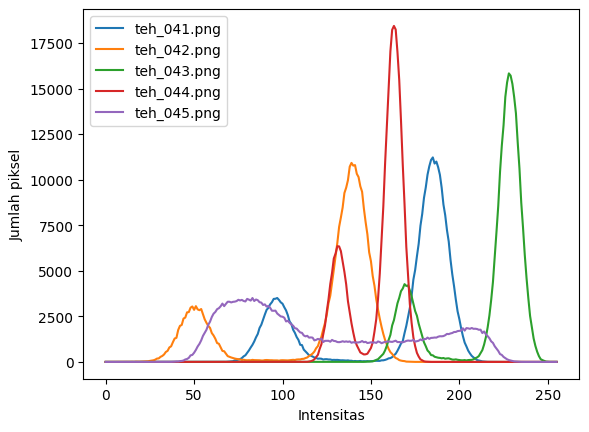

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from utils_cv import baca, statistik

for nama in ["teh_041.png", "teh_042.png", "teh_043.png",
             "teh_044.png", "teh_045.png"]:

    gray = cv2.cvtColor(
        baca(f"../data/sintetis/citra/{nama}"),
        cv2.COLOR_BGR2GRAY
    )

    print(nama, statistik(gray))

    hist = cv2.calcHist(
        [gray], [0], None, [256], [0, 256]
    )

    plt.plot(hist, label=nama)

plt.xlabel("Intensitas")
plt.ylabel("Jumlah piksel")
plt.legend()
plt.savefig("../hasil/b3_histogram_5kondisi.png")
plt.show()

3.3 PERBAIKAN CITRA

asli       KB=1.42 sigma=51.4
negatif    KB=1.42 sigma=51.4
cerah+50   KB=1.42 sigma=50.1
kontras    KB=1.42 sigma=72.9
regang     KB=1.46 sigma=80.5
gamma0.5   KB=1.24 sigma=36.6
gamma1.8   KB=1.76 sigma=55.7
ekualisasi KB=0.99 sigma=73.4
CLAHE      KB=1.68 sigma=44.8


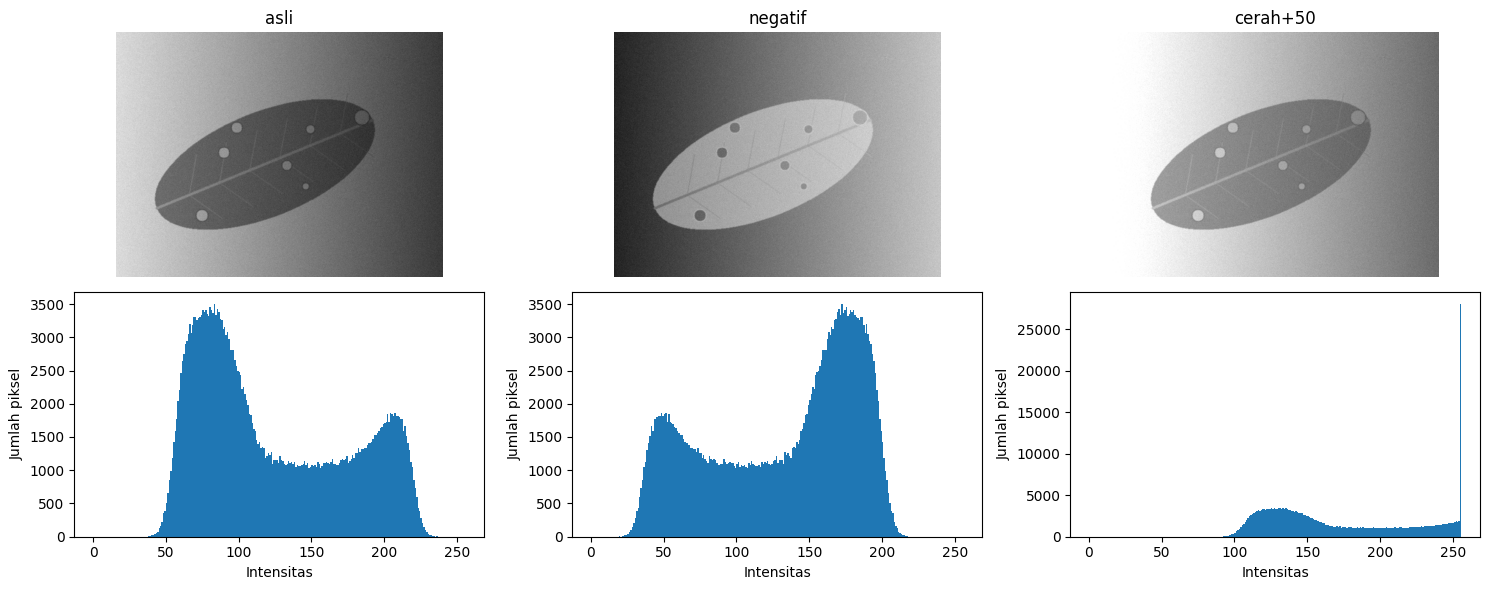

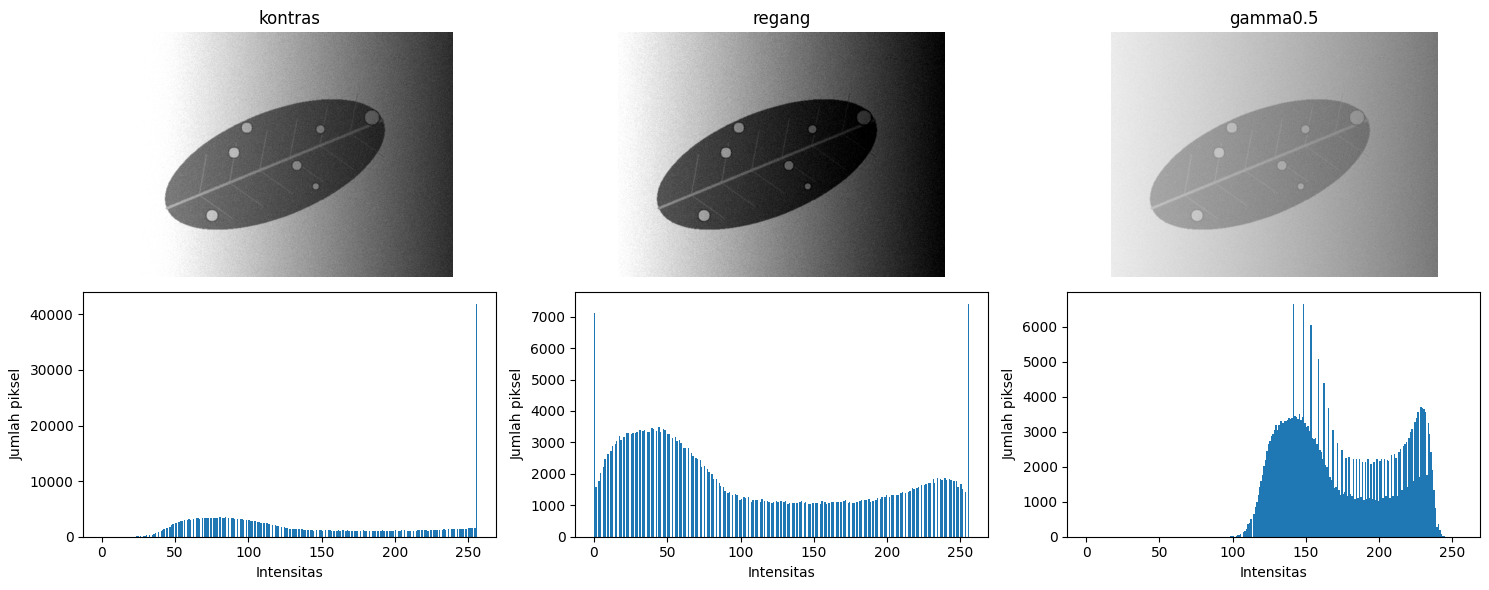

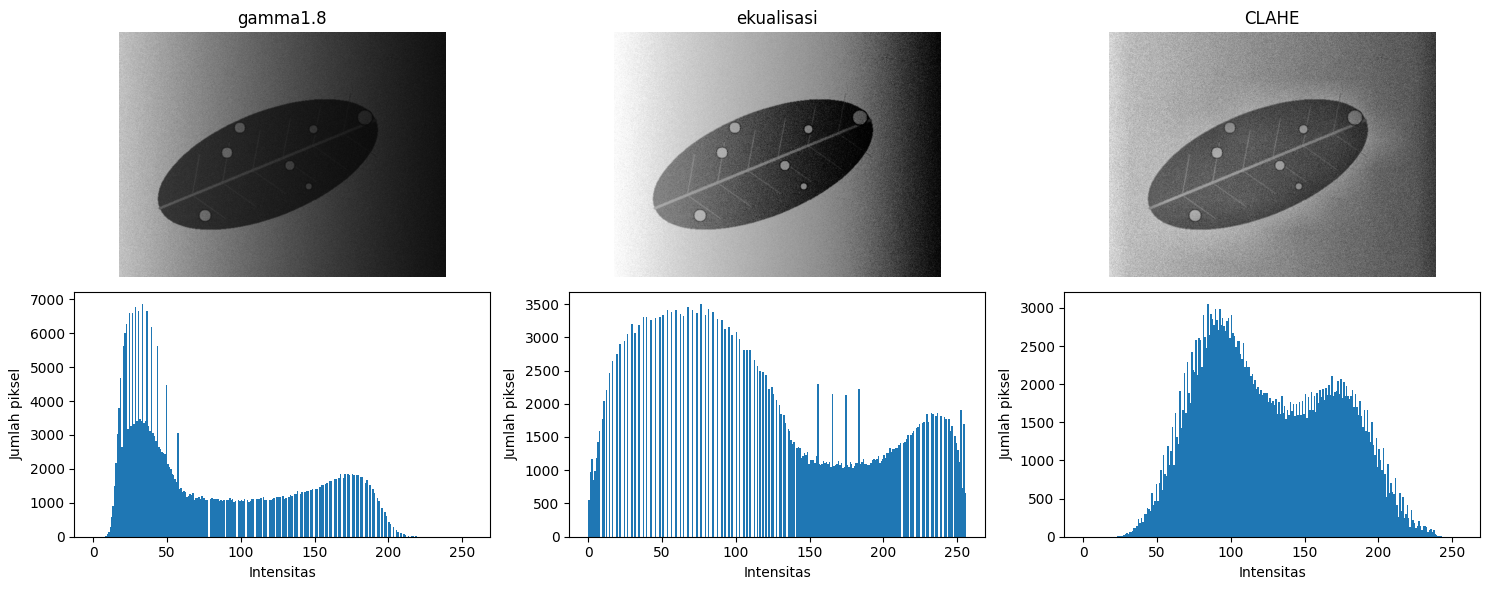

In [4]:
import cv2, numpy as np, matplotlib.pyplot as plt
from utils_cv import baca, kontras_bercak

nama = "teh_045.png"   # kondisi bayangan
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

rmin, rmax = np.percentile(gray, (2, 98))   # abaikan 2% piksel ekstrem
hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": np.clip((gray - rmin) / (rmax - rmin) * 255,
                      0, 255).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(clipLimit=2.0,
                             tileGridSize=(8, 8)).apply(gray),
}
for nm, c in hasil.items():
    print(f"{nm:10s} KB={kontras_bercak(c, md, mb):.2f} "
          f"sigma={c.std():.1f}")

# tampilkan tiap hasil bersama histogramnya (tata letak seperti Gambar 4)
daftar = list(hasil.items())
for i in range(0, len(daftar), 3):
    grup = daftar[i:i + 3]
    fig, ax = plt.subplots(2, 3, figsize=(15, 6))
    for j, (nm, c) in enumerate(grup):
        ax[0, j].imshow(c, cmap="gray", vmin=0, vmax=255)
        ax[0, j].set_title(nm); ax[0, j].axis("off")
        ax[1, j].hist(c.ravel(), bins=256, range=(0, 256))
        ax[1, j].set_xlabel("Intensitas"); ax[1, j].set_ylabel("Jumlah piksel")
    plt.tight_layout()
    plt.savefig(f"../hasil/b3_perbaikan_{i // 3 + 1}.png")
    plt.show()

3.4 Parameter CLAHE dan citra warna

clip=1.0 tile=4: KB=1.87
clip=1.0 tile=8: KB=1.85
clip=1.0 tile=16: KB=1.90
clip=2.0 tile=4: KB=1.92
clip=2.0 tile=8: KB=1.68
clip=2.0 tile=16: KB=1.76
clip=4.0 tile=4: KB=1.76
clip=4.0 tile=8: KB=1.40
clip=4.0 tile=16: KB=1.53


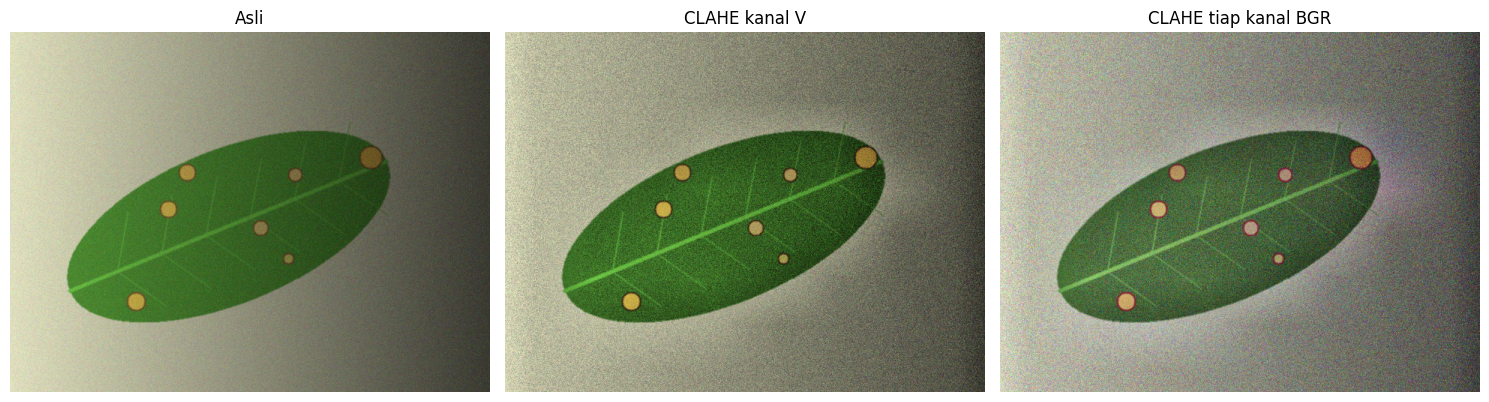

In [7]:
# Eksperimen parameter CLAHE
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        c = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(gray)
        print(f"clip={clip} tile={tile}: KB={kontras_bercak(c, md, mb):.2f}")

# CLAHE pada citra warna: kanal V dan tiap kanal BGR
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])

via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
via_bgr = cv2.merge([clahe.apply(c) for c in cv2.split(img)])

# Menampilkan perbandingan hasil CLAHE
daftar_clahe = [img, via_v, via_bgr]
judul_clahe = ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"]

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

for i in range(3):
    ax[i].imshow(cv2.cvtColor(daftar_clahe[i], cv2.COLOR_BGR2RGB))
    ax[i].set_title(judul_clahe[i])
    ax[i].axis("off")

plt.tight_layout()
plt.savefig("../hasil/b3_perbandingan_clahe.png")
plt.show()